# BRSET Vanilla Model Training

In [1]:
from pathlib import Path
import sys

ROOT = next(p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents) if (p / "pyproject.toml").exists())
DATA_PATH = ROOT / 'data'  / 'brset' / 'processed'
sys.path.insert(0, str(ROOT))

In [2]:
import os
os.environ["PROTOCOL_BUFFERS_PYTHON_IMPLEMENTATION"] = "python"
os.environ["KERAS_BACKEND"] = "tensorflow" # other options: tensorflow or torch

import keras_cv
import keras
import tensorflow as tf
import cv2
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("TensorFlow:", tf.__version__)
print("Keras:", keras.__version__)
print("KerasCV:", keras_cv.__version__)

TensorFlow: 2.18.1
Keras: 3.8.0
KerasCV: 0.9.0


In [3]:
class CFG:
    verbose = 1  # Verbosity
    seed = 48  # Random seed
    neg_sample = 0.3 # Downsample negative class
    pos_sample = 2.13  # Upsample positive class
    preset = "efficientnetv2_b2_imagenet"  # Name of pretrained classifier
    image_size = [256, 256]  # Input image size
    epochs = 8 # Training epochs
    batch_size = 128  # Batch size
    lr_mode = "cos" # LR scheduler mode from one of "cos", "step", "exp"
    class_names = ['target']
    num_classes = 1

keras.utils.set_random_seed(CFG.seed)

# 📖 | Meta Data


In [4]:
# Train + Valid
df = pd.read_parquet(f'{DATA_PATH}/train-metadata.parquet')
df = df.ffill()
display(df.head(2))

# Testing
testing_df = pd.read_parquet(f'{DATA_PATH}/test-metadata.parquet')
testing_df = testing_df.ffill()
display(testing_df.head(2))

,image_id,patient_id,camera,comorbidities,diabetes_time_y,insuline,exam_eye,diabetes,nationality,optic_disc,...,hemorrhage,retinal_detachment,myopic_fundus,increased_cup_disc,other,quality,age_approx,sex,anatom_site_general,target
0,img00001,1,Canon CR,diabetes1,12,yes,1,yes,Brazil,1,...,0,0,0,1,0,Adequate,48.0,male,right_eye,0
1,img00002,1,Canon CR,diabetes1,12,yes,2,yes,Brazil,2,...,0,0,0,1,0,Adequate,48.0,male,left_eye,0


,image_id,patient_id,camera,comorbidities,diabetes_time_y,insuline,exam_eye,diabetes,nationality,optic_disc,...,hemorrhage,retinal_detachment,myopic_fundus,increased_cup_disc,other,quality,age_approx,sex,anatom_site_general,target
0,img00011,6,Canon CR,diabetes1,5,yes,1,yes,Brazil,1,...,0,0,0,0,0,Adequate,14.0,male,right_eye,0
1,img00012,6,Canon CR,diabetes1,5,yes,2,yes,Brazil,1,...,0,0,0,0,0,Adequate,14.0,male,left_eye,0


# ⚖️ | Handle Class Imbalance

In [5]:
print(df['target'].value_counts())

target
0    12156
1      856
Name: count, dtype: int64


In [6]:
## Sample Data
print("Class Distribution Before Sampling (%):")
print(df.shape[0])
print(df.target.value_counts(normalize=True)*100)

# Sampling
positive_df = df.query("target==0").sample(frac=CFG.neg_sample, random_state=CFG.seed)
negative_df = df.query("target==1").sample(frac=CFG.pos_sample, replace=True, random_state=CFG.seed)
df = pd.concat([positive_df, negative_df], axis=0).sample(frac=1.0)

print("\nClass Distribution After Sampling (%):")
print(df.shape[0])
print(df.target.value_counts(normalize=True)*100)

Class Distribution Before Sampling (%):
13012
target
0    93.421457
1     6.578543
Name: proportion, dtype: float64

Class Distribution After Sampling (%):
5470
target
0    66.672761
1    33.327239
Name: proportion, dtype: float64


In [7]:
## Class Weight
from sklearn.utils.class_weight import compute_class_weight

class_weights = compute_class_weight('balanced', classes=np.unique(df['target']), y=df['target'])
class_weights = dict(enumerate(class_weights))
print("Class Weights:", class_weights)

Class Weights: {0: np.float64(0.7499314505072663), 1: np.float64(1.5002742731760834)}


# 🖼️ | Load Image Byte String


In [8]:
import h5py

training_validation_hdf5 = h5py.File(f"{DATA_PATH}/train-image.hdf5", 'r')
testing_hdf5 = h5py.File(f"{DATA_PATH}/test-image.hdf5", 'r')

Byte String: b'\xff\xd8\xff\xe0\x00\x10JFIF\x00\x01\x01\x00\x00\x01\x00\x01\x00\x00'....
Image:


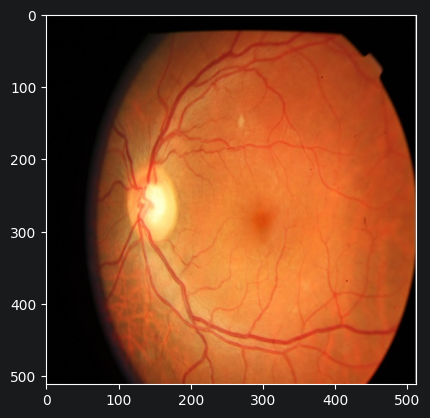

In [9]:
image_id = df.image_id.iloc[-10]

# Image as Byte String
byte_string = training_validation_hdf5[image_id][()]
print(f"Byte String: {byte_string[:20]}....")

# Convert byte string to numpy array
nparr = np.frombuffer(byte_string, np.uint8)

print("Image:")
image = cv2.imdecode(nparr, cv2.IMREAD_COLOR)[...,::-1] # reverse last axis for bgr -> rgb
plt.imshow(image);

# 🔪 | Data Split

In [10]:
from sklearn.model_selection import StratifiedGroupKFold

df = df.reset_index(drop=True) # ensure continuous index
df["fold"] = -1
sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=CFG.seed)
for i, (training_idx, validation_idx) in enumerate(sgkf.split(df, y=df.target, groups=df.patient_id)):
    df.loc[validation_idx, "fold"] = int(i)

# Use first fold for training and validation
training_df = df.query("fold!=0")
validation_df = df.query("fold==0")
print(f"# Num Train: {len(training_df)} | Num Valid: {len(validation_df)}")

# Num Train: 4376 | Num Valid: 1094


In [11]:
# class distribution in training and validation
print("training:", training_df.target.value_counts(),
      "\nvalidation:", validation_df.target.value_counts(), sep='\n')

training:
target
0    2918
1    1458
Name: count, dtype: int64

validation:
target
0    729
1    365
Name: count, dtype: int64


## 📊 | Tabular Features

In [12]:
df.dtypes

image_id                     object
patient_id                    int64
camera                       object
comorbidities                object
diabetes_time_y              object
insuline                     object
exam_eye                      int64
diabetes                     object
nationality                  object
optic_disc                   object
vessels                       int64
macula                        int64
dr_sdrg                       int64
dr_icdr                       int64
focus                         int64
illuminaton                   int64
image_field                   int64
artifacts                     int64
macular_edema                 int64
scar                          int64
nevus                         int64
amd                           int64
vascular_occlusion            int64
hypertensive_retinopathy      int64
drusens                       int64
hemorrhage                    int64
retinal_detachment            int64
myopic_fundus               

In [13]:
# Categorical features to be one hot encoded
CATEGORICAL_COLUMNS = ["sex", "anatom_site_general", 'diabetes', 'quality', 'optic_disc',
                       'insuline', 'nationality', 'diabetes_time_y', 'comorbidities', 'camera' ]

# Numerical features to be normalized
NUMERIC_COLUMNS = ["age_approx", "vascular_occlusion", "other", "increased_cup_disc", 'myopic_fundus',                      'retinal_detachment',"hemorrhage", "drusens", "hypertensive_retinopathy",                                 "macular_edema", "amd", "nevus", "scar", "artifacts", "image_field", "illuminaton", "focus", "dr_icdr", "dr_sdrg", "macula", "vessels", "exam_eye"]

# Tabular feature columns
FEAT_COLS = CATEGORICAL_COLUMNS + NUMERIC_COLUMNS

In [14]:
images_probe = [training_validation_hdf5[i][()] for i in training_df.image_id.values[:10]]

for x in images_probe:
  arr = np.asarray(x)
  print(type(x), arr.shape, arr.dtype)

<class 'numpy.bytes_'> () |S57628
<class 'numpy.bytes_'> () |S51223
<class 'numpy.bytes_'> () |S51618
<class 'numpy.bytes_'> () |S53872
<class 'numpy.bytes_'> () |S51173
<class 'numpy.bytes_'> () |S51663
<class 'numpy.bytes_'> () |S58821
<class 'numpy.bytes_'> () |S38338
<class 'numpy.bytes_'> () |S61040
<class 'numpy.bytes_'> () |S57696


## 🍚 | DataLoader

In [16]:
# Build Training & Validation sets
from src.isic24.input_pipeline import build_dataset

print("# Training:")
training_features = dict(training_df[FEAT_COLS])
training_ids = training_df.image_id.values
training_labels = training_df.target.values
training_ds = build_dataset(training_ids, training_validation_hdf5, training_features,
                         training_labels, batch_size=CFG.batch_size,
                         shuffle=True, augment=True)

print("# Validation:")
validation_features = dict(validation_df[FEAT_COLS])
validation_ids = validation_df.image_id.values
validation_labels = validation_df.target.values
validation_ds = build_dataset(validation_ids, training_validation_hdf5, validation_features,
                         validation_labels, batch_size=CFG.batch_size,
                         shuffle=False, augment=False)


# Training:


2026-06-23 15:38:07.461029: I metal_plugin/src/device/metal_device.cc:1154] Metal device set to: Apple M1
2026-06-23 15:38:07.461489: I metal_plugin/src/device/metal_device.cc:296] systemMemory: 16.00 GB
2026-06-23 15:38:07.461508: I metal_plugin/src/device/metal_device.cc:313] maxCacheSize: 5.92 GB
I0000 00:00:1782221887.462668 18458417 pluggable_device_factory.cc:305] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
I0000 00:00:1782221887.463065 18458417 pluggable_device_factory.cc:271] Created TensorFlow device (/job:localhost/replica:0/task:0/device:GPU:0 with 0 MB memory) -> physical PluggableDevice (device: 0, name: METAL, pci bus id: <undefined>)


# Validation:


In [19]:
feature_space = keras.utils.FeatureSpace(
    features={
        # Categorical features
        "sex": "string_categorical",
        "anatom_site_general": "string_categorical",
        "diabetes": "string_categorical",
        "quality": "string_categorical",
        "optic_disc": "string_categorical",
        "insuline": "string_categorical",
        "nationality": "string_categorical",
        "diabetes_time_y": "string_categorical",
        "comorbidities": "string_categorical",
        "camera": "string_categorical",

        # Numerical features
        "age_approx": "float_normalized",
        "vascular_occlusion": "float_normalized",
        "other": "float_normalized",
        "increased_cup_disc": "float_normalized",
        "myopic_fundus": "float_normalized",
        "retinal_detachment": "float_normalized",
        "hemorrhage": "float_normalized",
        "drusens": "float_normalized",
        "hypertensive_retinopathy": "float_normalized",
        "macular_edema": "float_normalized",
        "amd": "float_normalized",
        "nevus": "float_normalized",
        "scar": "float_normalized",
        "artifacts": "float_normalized",
        "image_field": "float_normalized",
        "illuminaton": "float_normalized",
        "focus": "float_normalized",
        "dr_icdr": "float_normalized",
        "dr_sdrg": "float_normalized",
        "macula": "float_normalized",
        "vessels": "float_normalized",
        "exam_eye": "float_normalized",
    },
    output_mode="concat",
)

## Adapt Tabular Features

In [ ]:
training_ds_with_no_labels = training_ds.map(lambda x, _: x["features"])
feature_space.adapt(training_ds_with_no_labels)

2026-06-23 15:55:03.496229: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:117] Plugin optimizer for device_type GPU is enabled.


In [ ]:
fs_dir = ROOT / 'artifacts' / 'feature_space'
fs_dir.mkdir(parents=True, exist_ok=True)

feature_space.save(os.path.join(fs_dir, 'brset_feature_space.keras'))
print(f"FeatureSpace saved at: '{fs_dir}'")

In [ ]:
# Apply Feature Processing

training_ds = training_ds.map(
    lambda x, y: ({"images": x["images"],
                   "features": feature_space(x["features"])}, y), num_parallel_calls=tf.data.AUTOTUNE)

validation_ds = validation_ds.map(
    lambda x, y: ({"images": x["images"],
                   "features": feature_space(x["features"])}, y), num_parallel_calls=tf.data.AUTOTUNE)

In [ ]:
# loss & metric
auc = keras.metrics.AUC(name='auc')
loss = keras.losses.BinaryCrossentropy(label_smoothing=0.02)

# 🤖 | Modeling

In [ ]:
# Define input layers
image_input = keras.Input(shape=(*CFG.image_size, 3), name="images")
feat_input = keras.Input(shape=(feature_space.get_encoded_features().shape[1],), name="features")
inp = {"images":image_input, "features":feat_input}

# Branch for image input
backbone = keras_cv.models.EfficientNetV2Backbone.from_preset(CFG.preset)
x1 = backbone(image_input)
x1 = keras.layers.GlobalAveragePooling2D()(x1)
x1 = keras.layers.Dropout(0.2)(x1)

# Branch for tabular/feature input
x2 = keras.layers.Dense(96, activation="selu")(feat_input)
x2 = keras.layers.Dense(128, activation="selu")(x2)
x2 = keras.layers.Dropout(0.1)(x2)

# Concatenate both branches
concat = keras.layers.Concatenate()([x1, x2])

# Output layer
out = keras.layers.Dense(1, activation="sigmoid", dtype="float32")(concat)

# Build model
model = keras.models.Model(inp, out)

# Compile the model
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-4),
    loss=loss,
    metrics=[auc],
)

# Model Summary
model.summary()

In [ ]:
# keras.utils.plot_model(model, show_shapes=True, show_layer_names=True, dpi=60)

# ⚓ | LR Schedule

## Sanity Checks

In [ ]:
inputs, targets = next(iter(training_ds))
images = inputs["images"]
num_images, NUMERIC_COLUMNS = 8, 4

plt.figure(figsize=(4 * NUMERIC_COLUMNS, num_images // NUMERIC_COLUMNS * 4))
for i, (image, target) in enumerate(zip(images[:num_images], targets[:num_images])):
    plt.subplot(num_images // NUMERIC_COLUMNS, NUMERIC_COLUMNS, i + 1)
    image = image.numpy().astype("float32")
    target= target.numpy().astype("int32")[0]

    image = (image - image.min()) / (image.max() + 1e-4)

    plt.imshow(image)
    plt.title(f"Target: {target}")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
from src.isic24.training import get_lr_callback
lr_cb = get_lr_callback(CFG.batch_size, mode="exp", plot=True)

In [ ]:
model_name = "best_vanilla_model.keras"
model_filepath = os.path.join(MODEL_PATH, model_name)

ckpt_cb = keras.callbacks.ModelCheckpoint(
    model_filepath,   # Filepath where the model will be saved.
    monitor="val_auc",    # Metric to monitor (validation AUC in this case).
    save_best_only=True,  # Save only the model with the best performance.
    save_weights_only=False,  # Save the entire model (not just the weights).
    mode="max",           # The model with the maximum 'val_auc' will be saved.
)

# 🚂 | Training

In [ ]:
history = model.fit(
    training_ds,
    epochs=CFG.epochs,
    callbacks=[lr_cb, ckpt_cb],
    validation_data=validation_ds,
    verbose=CFG.verbose,
    class_weight=class_weights,
)

In [ ]:
# save model

model.save(model_filepath, include_optimizer=True)
print(f"model saved at: {model_filepath}")

## Visualize AUC with Epochs

In [ ]:
# Extract AUC and validation AUC from history
auc = history.history['auc']
val_auc = history.history['val_auc']
epochs = range(1, len(auc) + 1)

# Find the epoch with the maximum val_auc
max_val_auc_epoch = np.argmax(val_auc)
max_val_auc = val_auc[max_val_auc_epoch]

# Plotting
plt.figure(figsize=(10, 6))
plt.plot(epochs, auc, 'o-', label='Training AUC', markersize=5, color='tab:blue')
plt.plot(epochs, val_auc, 's-', label='Validation AUC', markersize=5, color='tab:orange')

# Highlight the max val_auc
plt.scatter(max_val_auc_epoch + 1, max_val_auc, color='red', s=100, label=f'Max Val AUC: {max_val_auc:.4f}')
plt.annotate(f'Max Val AUC: {max_val_auc:.4f}',
             xy=(max_val_auc_epoch + 1, max_val_auc),
             xytext=(max_val_auc_epoch + 1 + 0.5, max_val_auc - 0.05),
             arrowprops=dict(facecolor='black', arrowstyle="->"),
             fontsize=12,
             color='tab:red')

# Enhancing the plot
plt.title('AUC over Epochs', fontsize=14)
plt.xlabel('Epoch', fontsize=12)
plt.ylabel('AUC', fontsize=12)
plt.legend(loc='lower right', fontsize=12)
plt.grid(True)
plt.xticks(epochs)

# Show the plot
plt.show()

# 📋 | Result

In [ ]:
# Best Result
best_score = max(history.history['val_auc'])
best_epoch = np.argmax(history.history['val_auc']) + 1
print("#" * 10 + " Result " + "#" * 10)
print(f"Best AUC: {best_score:.5f}")
print(f"Best Epoch: {best_epoch}")
print("#" * 28)

# 🧪 | Prediction

In [ ]:
model.load_weights(model_filepath)

In [ ]:
# Build Testing Dataset
# Don't forget to normalize for the testing data as well.

# Testing
print("# Testing:")
testing_features = dict(testing_df[FEAT_COLS])
testing_ids = testing_df.isic_id.values
testing_ds = build_dataset(testing_ids, testing_hdf5,
                        testing_features, batch_size=CFG.batch_size,
                         shuffle=False, augment=False, cache=False)

# Apply feature space processing
testing_ds = testing_ds.map(
    lambda x: {"images": x["images"],
               "features": feature_space(x["features"])}, num_parallel_calls=tf.data.AUTOTUNE)

In [ ]:
preds = model.predict(testing_ds).squeeze()

# set threshold
threshold = 0.5

# count positives
n_pos = np.sum(preds >= threshold)

print(f"Positive predictions: {n_pos}/{len(preds)}")
print(f"{100 * n_pos / len(preds):.2f}% positive predictions")


In [ ]:
inputs = next(iter(testing_ds))
images = inputs["images"]

idxs = np.random.choice(len(images), size=9, replace=False)

plt.figure(figsize=(10, 10))
for j, i in enumerate(idxs):
    plt.subplot(3, 3, j + 1)
    plt.imshow(images[i])
    plt.title(f'Pred: {preds[i]:.2f}')
    plt.axis('off')
plt.tight_layout(); plt.show()

In [ ]:
inputs = next(iter(testing_ds))
preds_batch = model.predict(inputs).squeeze()

images = inputs["images"]

pos_idxs = np.where(preds_batch >= 0.5)[0]

if len(pos_idxs) > 9:
    idxs = np.random.choice(pos_idxs, 9, replace=False)
else:
    idxs = pos_idxs

plt.figure(figsize=(10, 10))
for j, i in enumerate(idxs):
    plt.subplot(3, 3, j + 1)
    plt.imshow(images[i])
    plt.title(f'Pred: {preds_batch[i]:.2f}')
    plt.axis('off')

plt.tight_layout()
plt.show()

In [ ]:
# create a only positives predictions dataset
all_inputs = list(testing_ds.unbatch().as_numpy_iterator())
images = np.stack([x["images"] for x in all_inputs])
metadata = np.stack([x["metadata"] for x in all_inputs])

# predict
preds = model.predict({"images": images, "metadata": metadata}).squeeze()

# filter positives
pos_mask = preds >= 0.5
images_pos = images[pos_mask]
metadata_pos = metadata[pos_mask]

# rebuild dataset
positives_ds = tf.data.Dataset.from_tensor_slices({
    "images": images_pos,
    "metadata": metadata_pos
})